# PhishGuard: Phishing Website Detection Using Data Mining

## 1. Project Introduction and Objective

The objective of this project is to analyze website features
and detect phishing websites using data mining techniques.

## Dataset Source

UCI Machine Learning Repository — PhiUSIIL Phishing URL Dataset (ID 967, 2024).

https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset

## Algorithms

- Decision Tree
- Naive Bayes
- Support Vector Machine (SVM)

In [2]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

In [4]:
dataset = fetch_ucirepo(id=967)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset Shape:", df.shape)
print("Number of Samples:", df.shape[0])
print("Number of Features:", X.shape[1])
print("Target Column:", y.columns.tolist())

display(df.head())

Dataset Shape: (235795, 55)
Number of Samples: 235795
Number of Features: 54
Target Column: ['label']


# 2. Data Understanding

In this section, we investigate the dataset structure,
feature types, missing values, duplicate records,
and class distribution before preprocessing.

In [6]:
print("========== DATASET INFORMATION ==========")

print("Dataset Shape:", df.shape)
print("Number of Samples:", df.shape[0])
print("Number of Features:", X.shape[1])
print("Target Variable:", y.columns.tolist())

df.info()

========== DATASET INFORMATION ==========
Dataset Shape: (235795, 55)
Number of Samples: 235795
Number of Features: 54
Target Variable: ['label']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 55 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URL                         235795 non-null  object 
 1   URLLength                   235795 non-null  int64  
 2   Domain                      235795 non-null  object 
 3   DomainLength                235795 non-null  int64  
 4   IsDomainIP                  235795 non-null  int64  
 5   TLD                         235795 non-null  object 
 6   URLSimilarityIndex          235795 non-null  float64
 7   CharContinuationRate        235795 non-null  float64
 8   TLDLegitimateProb           235795 non-null  float64
 9   URLCharProb                 235795 non-null  float64
 10  TLDLength                   235795 non-nul

In [8]:
feature_info = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values,
    "Missing Values": df.isnull().sum().values
})

display(feature_info)

,Feature,Data Type,Unique Values,Missing Values
0,URL,object,235370,0
1,URLLength,int64,482,0
2,Domain,object,220086,0
3,DomainLength,int64,101,0
4,IsDomainIP,int64,2,0
5,TLD,object,695,0
6,URLSimilarityIndex,float64,36360,0
7,CharContinuationRate,float64,898,0
8,TLDLegitimateProb,float64,465,0
9,URLCharProb,float64,227421,0


In [10]:
print("Total Missing Values:", df.isnull().sum().sum())

missing_values = df.isnull().sum()

display(missing_values[missing_values > 0])

Total Missing Values: 0


,0


In [12]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate URLs:", df["URL"].duplicated().sum())


Duplicate Rows: 0
Duplicate URLs: 425


In [14]:
class_counts = df["label"].value_counts().sort_index()

class_percentages = df["label"].value_counts(
    normalize=True
).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

class_summary.index = ["Phishing", "Legitimate"]

display(class_summary)

,Count,Percentage
Phishing,100945,42.81
Legitimate,134850,57.19


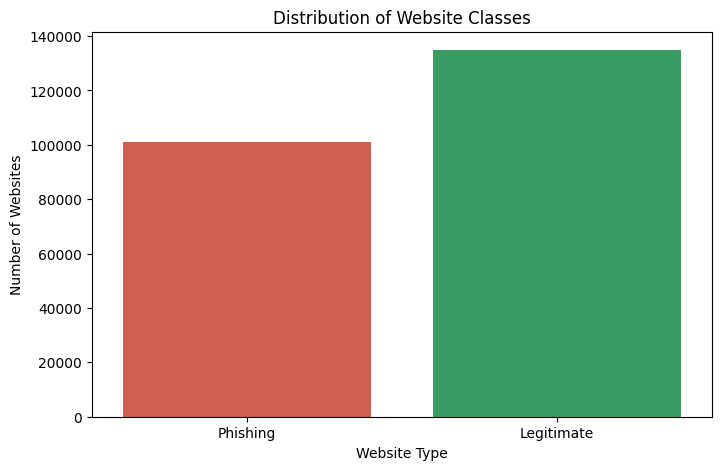

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_summary.index,
    y=class_summary["Count"],
    hue=class_summary.index,
    palette=["#e74c3c", "#27ae60"],
    legend=False
)

plt.title("Distribution of Website Classes")
plt.xlabel("Website Type")
plt.ylabel("Number of Websites")
plt.show()

# 3. Exploratory Data Analysis (EDA)

This section explores website characteristics, statistical
distributions, correlations, and potential outliers to
identify patterns associated with phishing websites.

In [18]:
from sklearn.model_selection import GroupShuffleSplit

groups = df["Domain"].astype(str).str.lower().str.strip()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=groups)
)

dev_df = df.iloc[train_idx].copy()
heldout_df = df.iloc[test_idx].copy()

eda_df = dev_df.copy()

eda_df["WebsiteType"] = eda_df["label"].map({
    0: "Phishing",
    1: "Legitimate"
})

print("Development samples:", len(dev_df))
print("Reserved test samples:", len(heldout_df))

print("Overlapping domains:", len(
    set(groups.iloc[train_idx]) &
    set(groups.iloc[test_idx])
))

Development samples: 189074
Reserved test samples: 46721
Overlapping domains: 0


In [20]:
display(eda_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
URLLength,189074.0,34.790627,43.768676,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,189074.0,21.453955,9.150833,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,189074.0,0.002671,0.051612,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,189074.0,78.291705,29.113422,0.155574,56.822477,100.000000,100.000000,1.000000e+02
CharContinuationRate,189074.0,0.845778,0.216320,0.000000,0.684211,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,189074.0,0.260470,0.251615,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,189074.0,0.055690,0.010604,0.001083,0.050629,0.057934,0.062847,9.082366e-02
TLDLength,189074.0,2.764024,0.601365,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,189074.0,1.163470,0.604703,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,189074.0,0.002020,0.044903,0.000000,0.000000,0.000000,0.000000,1.000000e+00


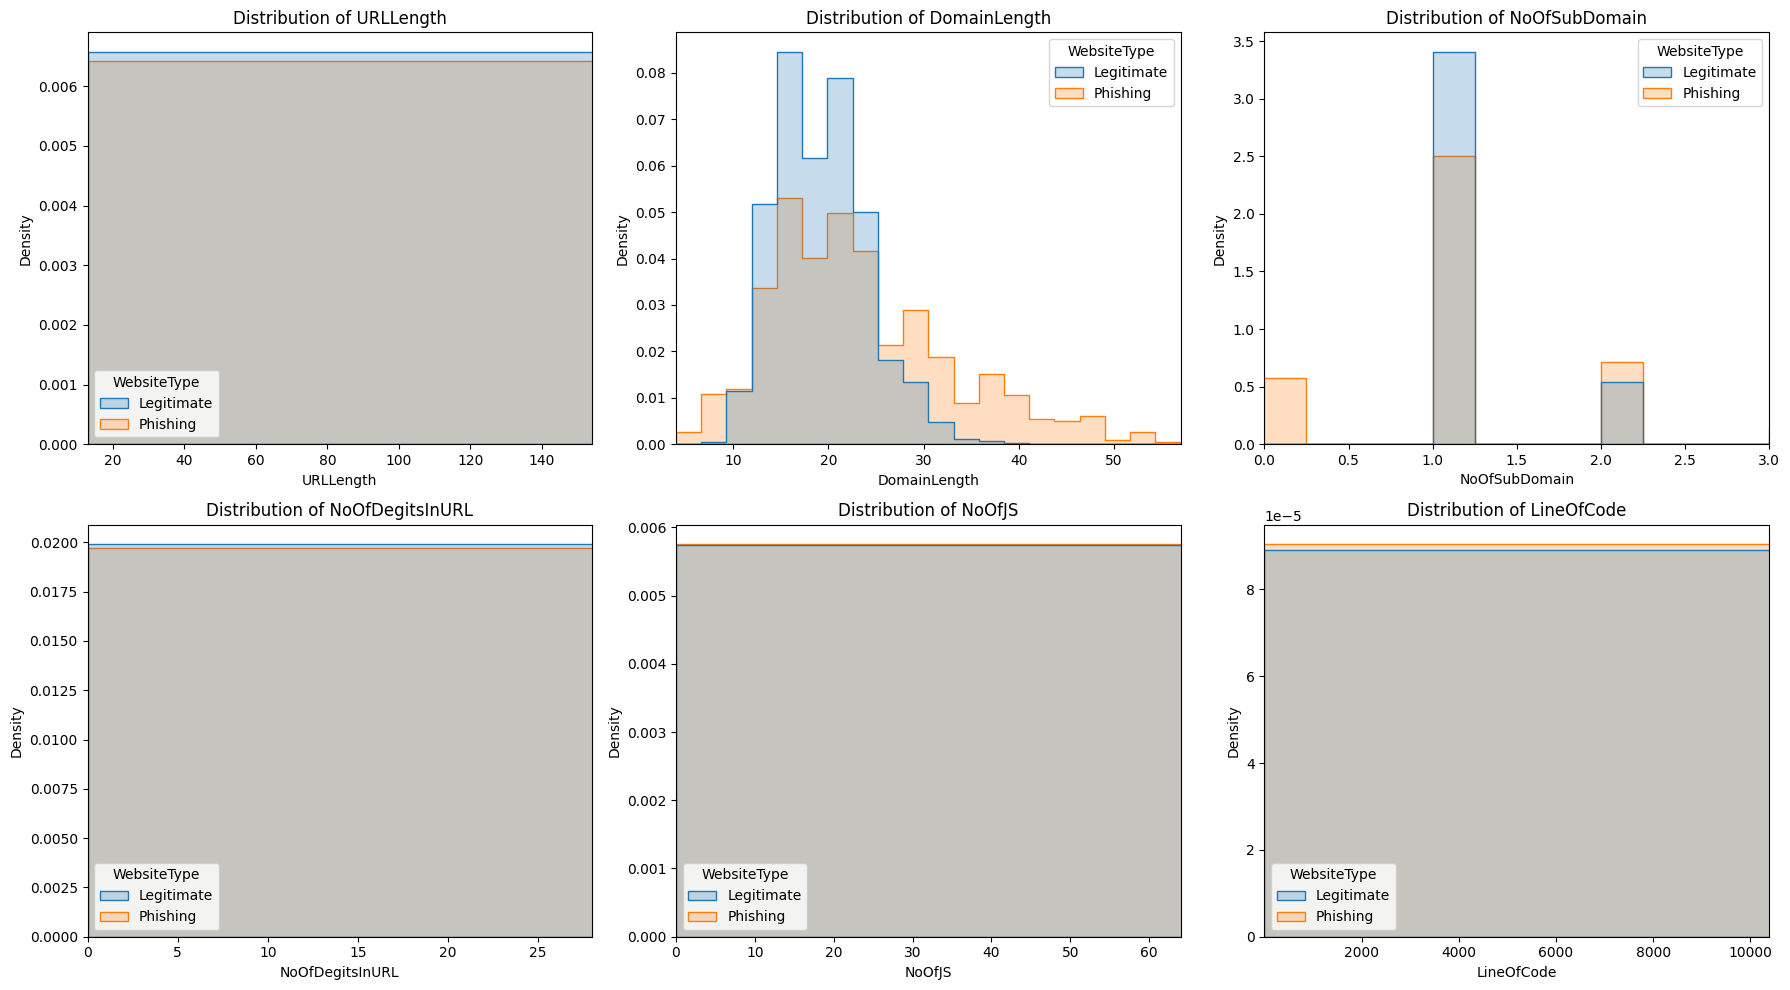

In [22]:
selected_features = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "NoOfDegitsInURL",
    "NoOfJS",
    "LineOfCode"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for feature, ax in zip(selected_features, axes.flatten()):

    sns.histplot(
        data=eda_df,
        x=feature,
        hue="WebsiteType",
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax
    )

    ax.set_xlim(
        eda_df[feature].min(),
        eda_df[feature].quantile(0.99)
    )

    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

WebsiteType,Legitimate,Phishing
IsHTTPS,,
0,0.00,100.00
1,72.94,27.06


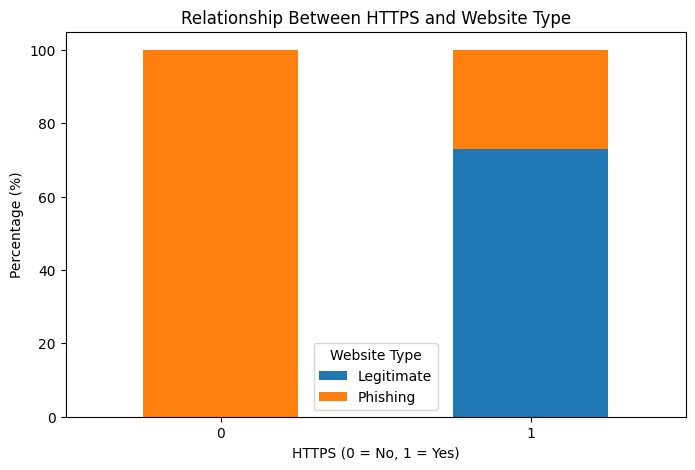

In [24]:
https_analysis = pd.crosstab(
    eda_df["IsHTTPS"],
    eda_df["WebsiteType"],
    normalize="index"
) * 100

display(https_analysis.round(2))

https_analysis.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Relationship Between HTTPS and Website Type")
plt.xlabel("HTTPS (0 = No, 1 = Yes)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Website Type")
plt.show()

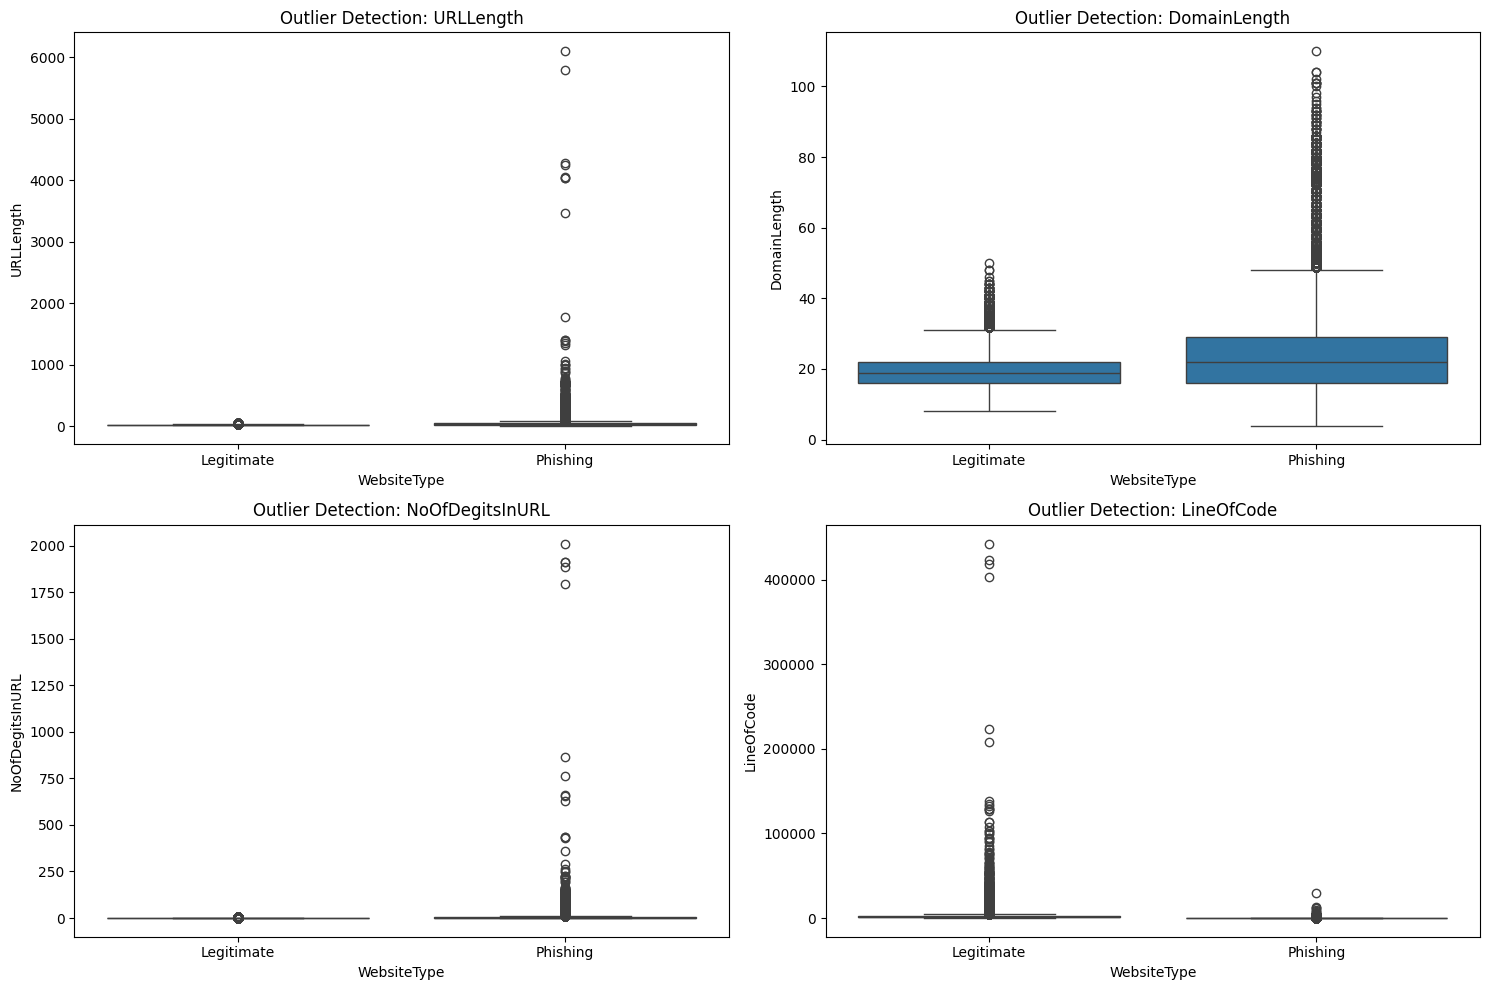

In [26]:
outlier_features = [
    "URLLength",
    "DomainLength",
    "NoOfDegitsInURL",
    "LineOfCode"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for feature, ax in zip(outlier_features, axes.flatten()):

    sns.boxplot(
        data=eda_df,
        x="WebsiteType",
        y=feature,
        ax=ax
    )

    ax.set_title(f"Outlier Detection: {feature}")

plt.tight_layout()
plt.show()

,Correlation
URLSimilarityIndex,-0.859929
HasSocialNet,-0.785108
HasCopyrightInfo,-0.742307
HasDescription,-0.690708
IsHTTPS,-0.607861
DomainTitleMatchScore,-0.585779
HasSubmitButton,-0.575929
IsResponsive,-0.551594
URLTitleMatchScore,-0.539443
SpacialCharRatioInURL,0.533386


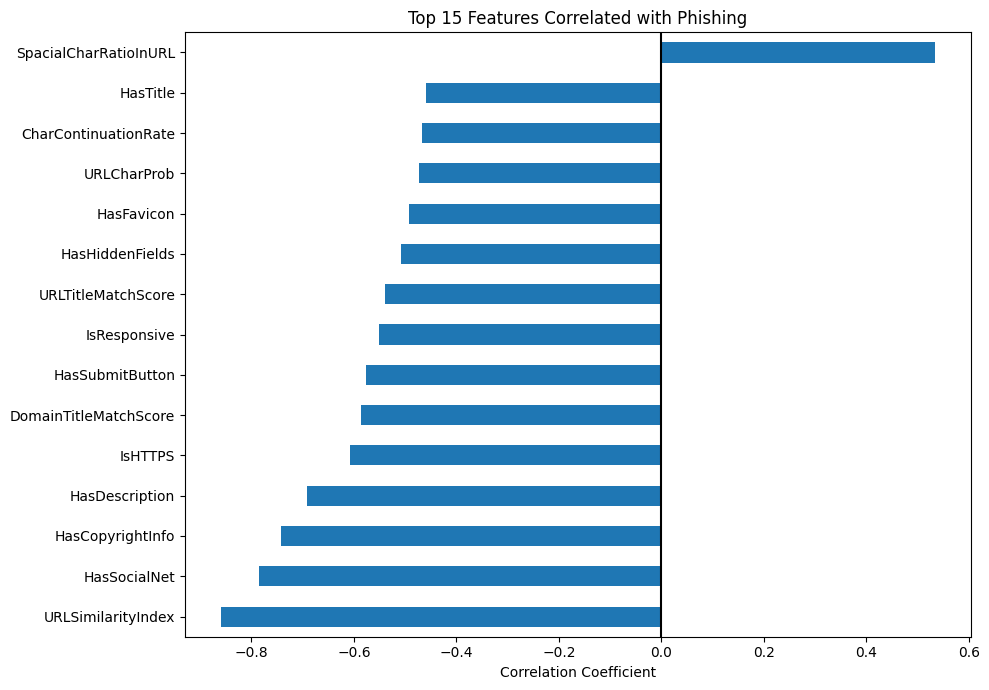

In [28]:
numeric_data = eda_df.select_dtypes(
    include=np.number
).copy()

numeric_data["IsPhishing"] = 1 - numeric_data["label"]

numeric_data = numeric_data.drop(columns=["label"])

correlation_matrix = numeric_data.corr()

target_correlation = (
    correlation_matrix["IsPhishing"]
    .drop("IsPhishing")
    .dropna()
)

top_features = (
    target_correlation.abs()
    .sort_values(ascending=False)
    .head(15)
    .index
)

display(
    target_correlation.loc[top_features]
    .to_frame("Correlation")
)

plt.figure(figsize=(10, 7))

target_correlation.loc[top_features].sort_values().plot(
    kind="barh"
)

plt.axvline(0, color="black")

plt.title("Top 15 Features Correlated with Phishing")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.show()

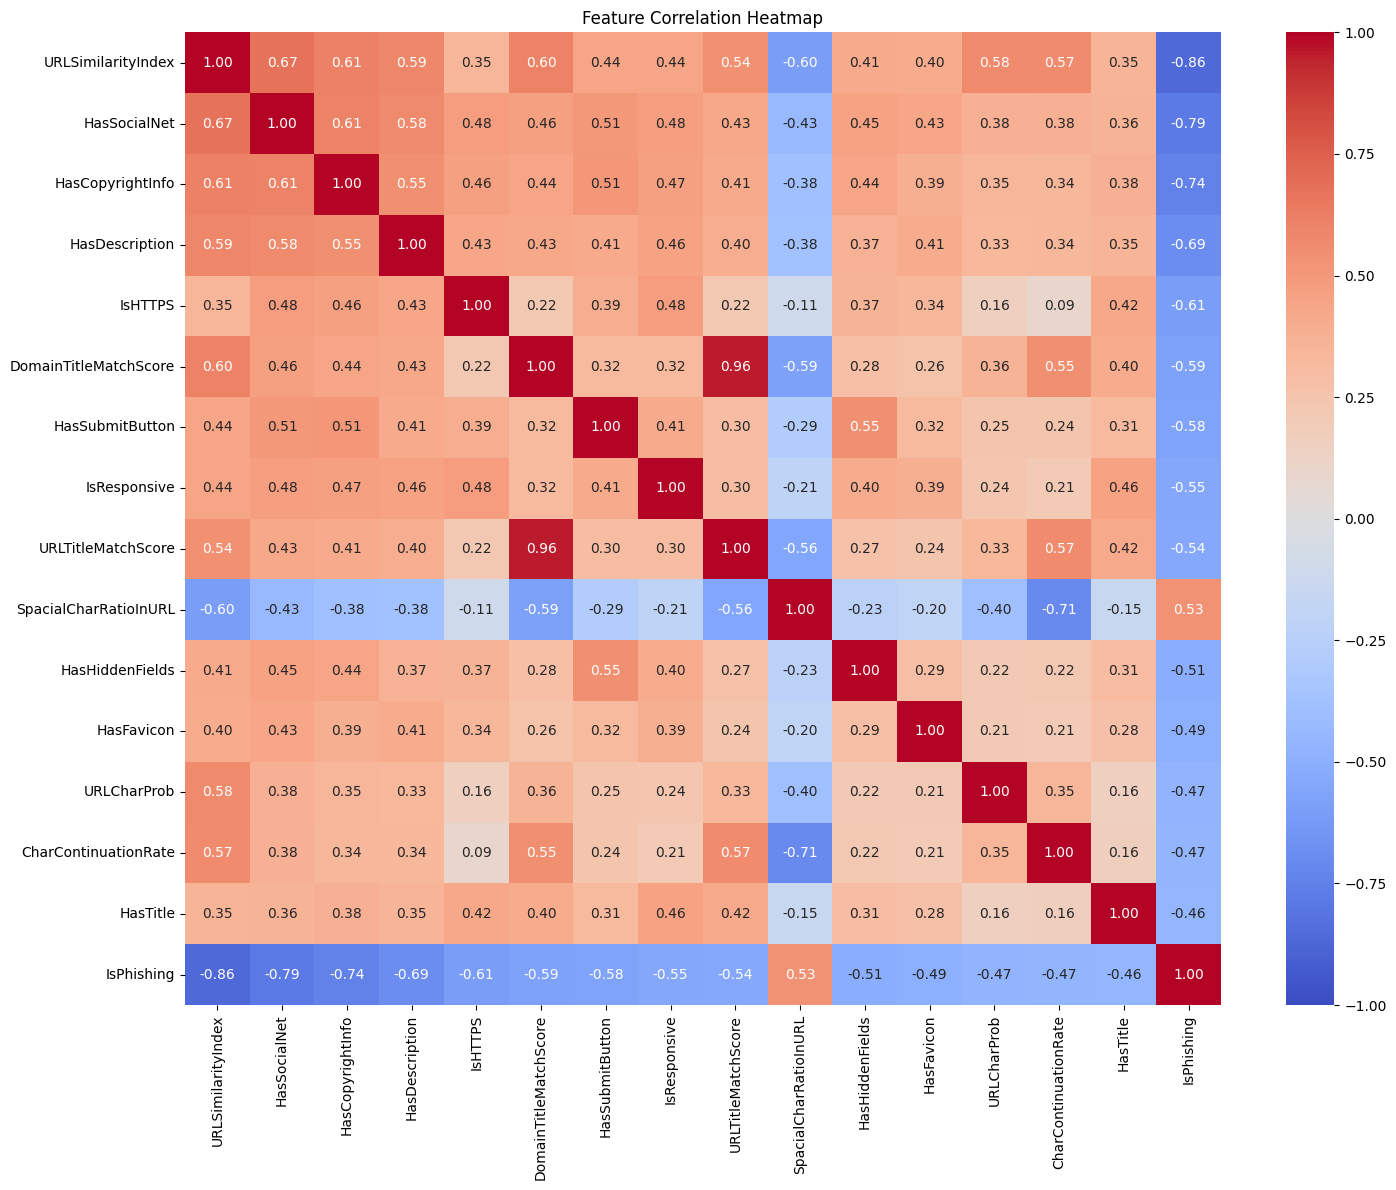

In [30]:
heatmap_features = list(top_features) + ["IsPhishing"]

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation_matrix.loc[
        heatmap_features,
        heatmap_features
    ],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# 4. Data Cleaning and Preprocessing

This section prepares the dataset by handling missing
values, duplicate records, outliers, categorical
variables, feature scaling, and class imbalance.

Preprocessing parameters are learned from training
data only to prevent data leakage.

In [32]:
def clean_data(data):
    data = data.copy()
    data["URL"] = data["URL"].str.strip()
    data = data.dropna(subset=["URL", "label"])
    data = data[data["URL"] != ""]
    return data.drop_duplicates(subset="URL").reset_index(drop=True)

clean_dev = clean_data(dev_df)
clean_test = clean_data(heldout_df)

clean_dev = clean_dev[~clean_dev["URL"].isin(clean_test["URL"])]

print("Original samples:", len(df))
print("Clean development samples:", len(clean_dev))
print("Clean test samples:", len(clean_test))
print("Removed records:", len(df) - len(clean_dev) - len(clean_test))
print("Missing values:", clean_dev.isnull().sum().sum())
print("Overlapping URLs:", len(set(clean_dev["URL"]) & set(clean_test["URL"])))

outlier_columns = ["URLLength", "DomainLength", "NoOfDegitsInURL",
                   "NoOfSubDomain", "NoOfJS", "LineOfCode"]

Q1 = clean_dev[outlier_columns].quantile(0.25)
Q3 = clean_dev[outlier_columns].quantile(0.75)
IQR = Q3 - Q1

outliers = ((clean_dev[outlier_columns] < Q1 - 1.5 * IQR) |
            (clean_dev[outlier_columns] > Q3 + 1.5 * IQR)).sum()

display(outliers.to_frame("Outlier Count"))

display(clean_dev["label"].value_counts(normalize=True)
        .mul(100).rename(index={0: "Phishing", 1: "Legitimate"})
        .to_frame("Percentage"))

Original samples: 235795
Clean development samples: 188738
Clean test samples: 46632
Removed records: 425
Missing values: 0
Overlapping URLs: 0


,Outlier Count
URLLength,18328
DomainLength,10707
NoOfDegitsInURL,41495
NoOfSubDomain,46306
NoOfJS,9560
LineOfCode,15414


,Percentage
label,
Legitimate,57.183503
Phishing,42.816497


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

def build_preprocessor(log_columns, numerical_columns, categorical_columns):

    log_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p)),
        ("scaler", StandardScaler())
    ])

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore",
                                  max_categories=30,
                                  sparse_output=False))
    ])

    return ColumnTransformer([
        ("log", log_pipeline, log_columns),
        ("numeric", numerical_pipeline, numerical_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ])

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


# 5. Feature Engineering

This section extracts additional URL-based features
to improve phishing website classification and support
the analysis of new URLs without visiting websites.

In [35]:
from urllib.parse import urlsplit
from collections import Counter

def extract_features(url):
    parsed = urlsplit(url)
    length = max(len(url), 1)
    probabilities = np.array(list(Counter(url).values())) / length

    return {
        "URL_Entropy": -np.sum(probabilities * np.log2(probabilities)),
        "Digit_Ratio": sum(c.isdigit() for c in url) / length,
        "Special_Ratio": sum(not c.isalnum() for c in url) / length,
        "Path_Depth": len([p for p in parsed.path.split("/") if p]),
        "Query_Count": len(parsed.query.split("&")) if parsed.query else 0,
        "Path_Length": len(parsed.path)
    }

for data in [clean_dev, clean_test]:
    features = pd.DataFrame(
        data["URL"].apply(extract_features).tolist(),
        index=data.index
    )
    data[features.columns] = features

display(clean_dev[features.columns].head())

print("New features added:", len(features.columns))

,URL_Entropy,Digit_Ratio,Special_Ratio,Path_Depth,Query_Count,Path_Length
0,3.929229,0.0,0.156250,0,0,0
1,3.970176,0.0,0.250000,0,0,0
2,4.164735,0.0,0.200000,0,0,0
3,4.060262,0.0,0.185185,0,0,0
4,3.917626,0.0,0.147059,0,0,0


New features added: 6


# 6. Feature Selection and Information Gain

This section selects reproducible URL-based features
and measures their information gain to identify
the most informative characteristics of phishing URLs.

,Information Gain
HTTPS,0.331055
Host_Suffix,0.262061
URL_Length,0.222719
Digit_Ratio,0.205725
URL_Entropy,0.185797
Path_Length,0.160101
Host_Length,0.101514
Path_Depth,0.090485
Special_Ratio,0.029557
Query_Count,0.000000


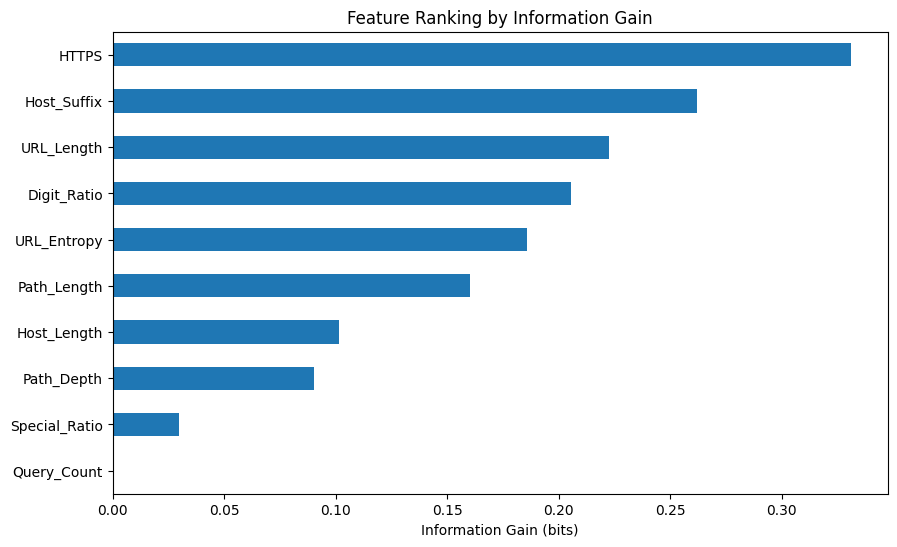

Selected features: 10


In [37]:
from sklearn.metrics import mutual_info_score

def basic_features(url):
    parsed = urlsplit(url)
    host = parsed.hostname or ""
    suffix = host.rsplit(".", 1)[-1] if "." in host else "unknown"

    return {
        "URL_Length": len(url),
        "Host_Length": len(host),
        "HTTPS": int(parsed.scheme.lower() == "https"),
        "Host_Suffix": suffix if suffix.isalpha() else "unknown"
    }

for data in [clean_dev, clean_test]:
    extra = pd.DataFrame(
        data["URL"].apply(basic_features).tolist(),
        index=data.index
    )
    data[extra.columns] = extra

log_columns = ["URL_Length", "Host_Length", "Path_Depth",
               "Path_Length", "Query_Count"]

numerical_columns = ["URL_Entropy", "Digit_Ratio",
                     "Special_Ratio", "HTTPS"]

categorical_columns = ["Host_Suffix"]

selected_columns = log_columns + numerical_columns + categorical_columns

scores = {}

for col in selected_columns:
    values = clean_dev[col]

    if pd.api.types.is_numeric_dtype(values) and values.nunique() > 10:
        values = pd.qcut(values, q=10, duplicates="drop")

    values = values.astype("string").fillna("Missing")
    scores[col] = mutual_info_score(clean_dev["label"], values) / np.log(2)

importance = pd.Series(scores).sort_values(ascending=False)

display(importance.to_frame("Information Gain"))

importance.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title("Feature Ranking by Information Gain")
plt.xlabel("Information Gain (bits)")
plt.show()

print("Selected features:", len(selected_columns))

# 7. Train/Test Split

The dataset is divided into development and testing
sets using domain-based splitting to reduce data leakage.

In [39]:
X_train = clean_dev[selected_columns]
X_test = clean_test[selected_columns]

y_train = 1 - clean_dev["label"]
y_test = 1 - clean_test["label"]

train_groups = clean_dev["Domain"].astype(str).str.lower().str.strip()

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)
print("Training class distribution:")
print(y_train.value_counts(normalize=True))

Training samples: (188738, 10)
Testing samples: (46632, 10)
Training class distribution:
label
0    0.571835
1    0.428165
Name: proportion, dtype: float64


# 8–9. Model Training and Hyperparameter Tuning

Three classification algorithms are trained and tuned
using Grid Search and group-based cross-validation.
The F1-score is used to select the best parameters.

In [41]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

models = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"model__max_depth": [10, 20]}
    ),
    "Naive Bayes": (
        GaussianNB(),
        {"model__var_smoothing": [1e-9, 1e-6]}
    ),
    "SVM": (
        LinearSVC(dual=False, max_iter=5000, random_state=42),
        {"model__C": [0.1, 1]}
    )
}

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
trained_models = {}

for name, (model, params) in models.items():

    pipeline = Pipeline([
        ("preprocessing", build_preprocessor(
            log_columns, numerical_columns, categorical_columns
        )),
        ("model", model)
    ])

    search = GridSearchCV(pipeline, params, cv=cv, scoring="f1")

    search.fit(X_train, y_train, groups=train_groups)

    trained_models[name] = search.best_estimator_

    print(name)
    print("Best Parameters:", search.best_params_)
    print("CV F1-score:", round(search.best_score_, 4))
    print("-" * 40)

Decision Tree
Best Parameters: {'model__max_depth': 20}
CV F1-score: 0.9942
----------------------------------------
Naive Bayes
Best Parameters: {'model__var_smoothing': 1e-09}
CV F1-score: 0.987
----------------------------------------
SVM
Best Parameters: {'model__C': 1}
CV F1-score: 0.9935
----------------------------------------


# 10. Model Evaluation and Comparison

The trained models are evaluated on unseen test data
using Accuracy, Precision, Recall, F1-score, ROC-AUC,
and Confusion Matrices.

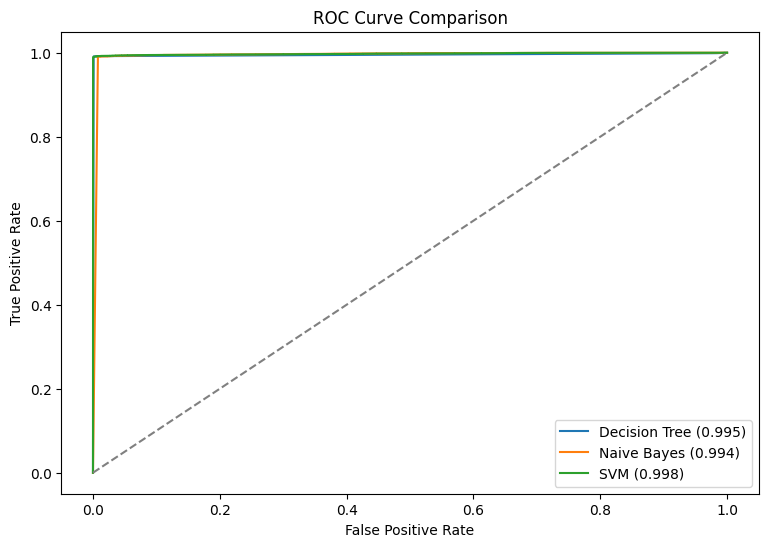

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Decision Tree,0.9956,0.9984,0.9912,0.9948,0.9949
Naive Bayes,0.9905,0.9867,0.9908,0.9888,0.9939
SVM,0.9949,0.9998,0.9880,0.9939,0.9976


In [43]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    ConfusionMatrixDisplay
)

results = {}
predictions = {}

plt.figure(figsize=(9, 6))

for name, model in trained_models.items():

    pred = model.predict(X_test)
    predictions[name] = pred

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores)
    }

    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} ({results[name]['ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

results_df = pd.DataFrame(results).T
display(results_df.round(4))

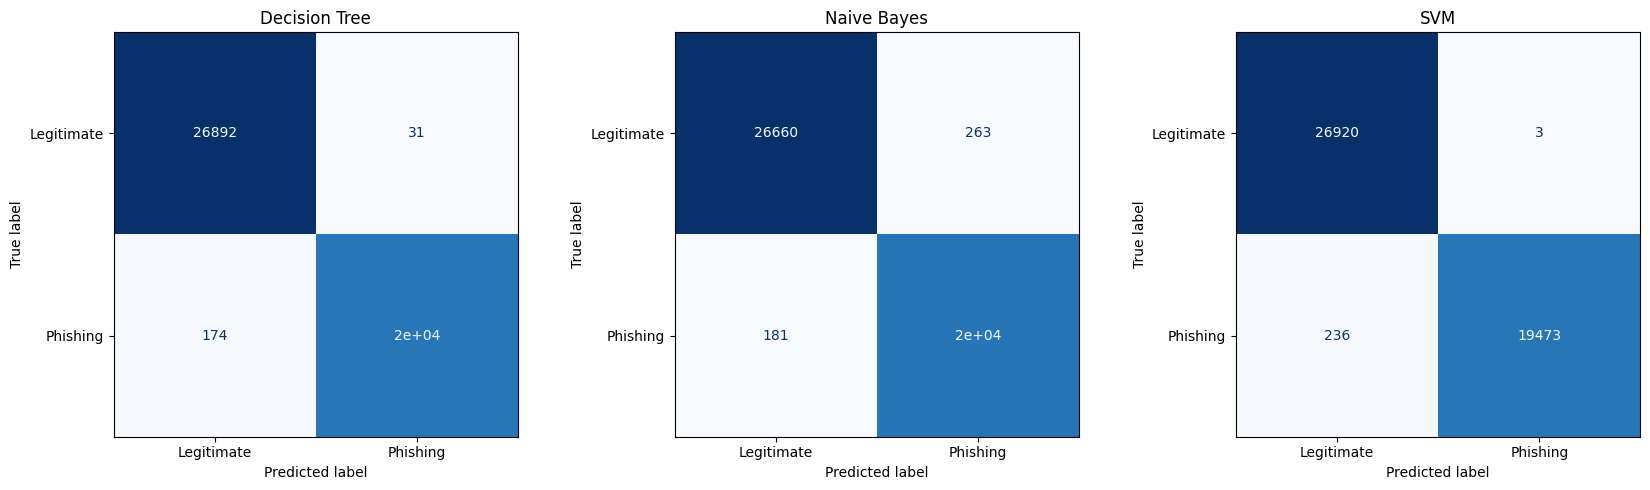

Highest Test F1-score: Decision Tree


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Decision Tree,0.9956,0.9984,0.9912,0.9948,0.9949
SVM,0.9949,0.9998,0.9880,0.9939,0.9976
Naive Bayes,0.9905,0.9867,0.9908,0.9888,0.9939


In [45]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for (name, pred), ax in zip(predictions.items(), axes):

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        labels=[0, 1],
        display_labels=["Legitimate", "Phishing"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

print("Highest Test F1-score:", results_df["F1-score"].idxmax())

display(results_df.sort_values("F1-score", ascending=False).round(4))

results_df.to_csv("model_comparison.csv")

# 11. Results and Discussion

This section compares model performance, identifies
important features, and analyzes classification errors.

In [47]:
from sklearn.metrics import confusion_matrix

best_test_name = results_df["F1-score"].idxmax()

print("Highest Test F1-score:", best_test_name)
display(results_df.loc[best_test_name].to_frame("Score"))

print("Top 5 Features by Information Gain:")
display(importance.head(5).to_frame("Information Gain"))

for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    print(f"{name}: False Positives = {fp}, False Negatives = {fn}")

Highest Test F1-score: Decision Tree


,Score
Accuracy,0.995604
Precision,0.998416
Recall,0.991172
F1-score,0.994780
ROC-AUC,0.994894


Top 5 Features by Information Gain:


,Information Gain
HTTPS,0.331055
Host_Suffix,0.262061
URL_Length,0.222719
Digit_Ratio,0.205725
URL_Entropy,0.185797


Decision Tree: False Positives = 31, False Negatives = 174
Naive Bayes: False Positives = 263, False Negatives = 181
SVM: False Positives = 3, False Negatives = 236


## Conclusion and Limitations

The Decision Tree achieved the highest cross-validation F1-score (99.42%) and test F1-score (99.48%), with 99.56% test accuracy. It made 205 errors, including 31 false positives and 174 false negatives. SVM achieved the highest ROC-AUC (99.76%) and precision (99.98%), but missed more phishing URLs (236). The Decision Tree was preferred because it achieved the best F1-score and recall among the three models.

Information Gain ranked HTTPS, host suffix, URL length, digit ratio and URL entropy as the five most informative individual features. The exploratory analysis also showed that all non-HTTPS records in the development set were labeled phishing, while 27.06% of HTTPS records were phishing. This may reflect dataset collection bias; HTTPS alone does not guarantee safety.

The model uses ten URL-based features, and the domain-based split prevents overlap of the exact normalized domain strings recorded in the dataset. Related subdomains, dataset-specific patterns and collection biases may still affect performance. The results do not establish real-world accuracy on newer independent datasets.

## 12. Export trained models for the Streamlit demo
Run this cell after training and evaluation. It exports the original fitted pipelines, measured metrics, and runtime dependencies. This is a portfolio/deployment addition, not part of the academic submission.

In [ ]:
# Run only after Sections 8–11 have completed successfully.
import sys
import json
import zipfile
import pickle
from importlib.metadata import version
from pathlib import Path

required = ("trained_models", "extract_features", "basic_features", "selected_columns", "results_df")
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Run the training and evaluation cells first. Missing: " + ", ".join(missing))

with open("models.pkl", "wb") as f:
    pickle.dump({"format": "phishguard-models-v1", "models": trained_models, "columns": list(selected_columns)}, f, protocol=4)
results_df.to_csv("model_comparison.csv")

# Match the runtime used to serialize the scikit-learn pipelines.
packages = ["numpy", "pandas", "scipy", "scikit-learn", "cloudpickle", "joblib", "threadpoolctl"]
versions = {name: version(name) for name in packages}
requirements = "streamlit==1.51.0\n" + "\n".join(f"{name}=={v}" for name, v in versions.items()) + "\n"
Path("requirements.txt").write_text(requirements, encoding="utf-8")
python_version = f"{sys.version_info.major}.{sys.version_info.minor}"
Path("model_environment.json").write_text(json.dumps({"python": python_version, "packages": versions}, indent=2), encoding="utf-8")

# Verify the exported bundle in the same runtime with a harmless example.
with open("models.pkl", "rb") as f:
    bundle = pickle.load(f)
    saved_models, columns = bundle["models"], bundle["columns"]
example = "https://example.com"
features = pd.DataFrame([{**extract_features(example), **basic_features(example)}])[columns]
assert all(int(m.predict(features)[0]) == int(trained_models[name].predict(features)[0]) for name, m in saved_models.items())

with zipfile.ZipFile("PhishGuard_Deployment_Files.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in ["models.pkl", "model_comparison.csv", "requirements.txt", "model_environment.json"]:
        z.write(name)
print("Export verified. Deployment Python version:", python_version)
from google.colab import files
files.download("PhishGuard_Deployment_Files.zip")
